<a href="https://colab.research.google.com/github/luisavgonzalez27/ads-509-Final-Project/blob/main/02_MAUDE_Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAUDE Medical Device Adverse Event Data Collection

## Notebook 02 - MAUDE_Text_Classification

Uses FDA MAUDE narratives to classify Malfunction, Injury, or Death, using text embeddings.

* Examines narrative length and top bigrams by event type.
* Splits the cleaned data into approximately 80% training and 20% testing using a group-aware split based on normalized narrative text.
* Converts narratives into numerical representations using a pretrained Sentence-BERT model.
* Trains and evaluates a multiclass logistic regression model using the Sentence-BERT embeddings.
* Compares the results with a weighted balanced logistic regression model.
* Misclassified reports are examined individually to better understand where the model has difficulty distinguishing between event types.

## Key Findings

- The standard Sentence-BERT + Logistic Regression model achieved 97.41% accuracy and a 0.9540 macro F1-score on the 193-report test set.

- The standard model achieved F1-scores of 0.9854 for Malfunction, 0.9733 for Injury, and 0.9032 for Death.

- The balanced Sentence-BERT + Logistic Regression model also achieved 97.41% accuracy but produced a higher macro F1-score of 0.9638.

- Class weighting increased Death recall from 82.35% to 88.24% and Death F1 from 0.9032 to 0.9375 while maintaining 100% Death precision. Both models misclassified only 5 of the 193 test reports.

- The balanced model provided more consistent performance across the three event types. It achieved F1-scores of 0.9802 for Malfunction, 0.9737 for Injury, and 0.9375 for Death.

- Error analysis of the balanced model identified five misclassified reports: two Malfunction reports were classified as Injury, one Injury report was classified as Malfunction, one Death report was classified as Malfunction, and one Death report was classified as Injury. Some errors involved narratives containing characteristics of multiple event types, while one Death-labeled report did not explicitly mention a patient death in the available narrative.



In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,precision_recall_fscore_support)
from sklearn.feature_extraction.text import (CountVectorizer,ENGLISH_STOP_WORDS)
from sklearn.model_selection import GroupShuffleSplit
import os

In [46]:
#load data
df = pd.read_csv("fda_cgm_reports_clean.csv")

print(df.shape)
print(df["event_type"].value_counts())
df.head(2)

(951, 10)
event_type
Malfunction    498
Injury         366
Death           87
Name: count, dtype: int64


,report_id,date_received,brand_name,generic_name,manufacturer,product_code,narrative,event_type,product_problems,patient_problems
0,3004753838-2020-038805,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,"['Premature End-of-Life Indicator', 'Premature End-of-Life Indicator']","['No Consequences Or Impact To Patient', 'No Consequences Or Impact To Patient']"
1,3004753838-2020-038806,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,"['Wireless Communication Problem', 'Wireless Communication Problem']","['No Consequences Or Impact To Patient', 'No Consequences Or Impact To Patient']"


Examine narrative length by event type

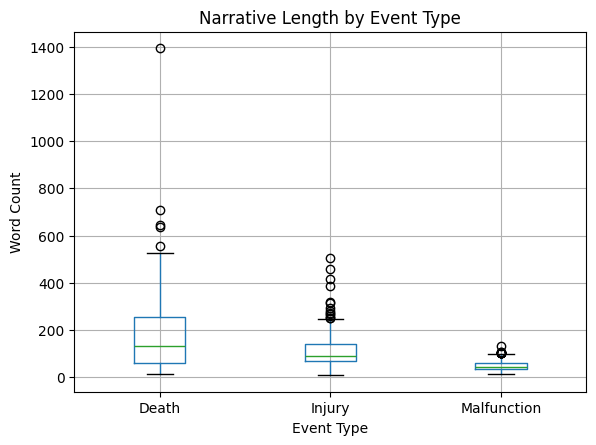

In [47]:
#plot narrative length by event type
df["word_count"] = df["narrative"].fillna("").str.split().str.len()
df["character_count"] = df["narrative"].fillna("").str.len()

df.boxplot(column="word_count", by="event_type")

plt.title("Narrative Length by Event Type")
plt.suptitle("")
plt.xlabel("Event Type")
plt.ylabel("Word Count")
plt.show()

Examine the top bigrams by event type

In [48]:
# remove filler words
custom_stop_words = list(
    ENGLISH_STOP_WORDS.union({
        "reported",
        "information",
        "available",
        "additional",
        "event",
        "provided",
        "occurred"}))

def get_top_bigrams(data, event_type, n=15):

    texts = data.loc[
        data["event_type"] == event_type,
        "narrative"
    ].dropna()

    vectorizer = CountVectorizer(
        stop_words=custom_stop_words,
        ngram_range=(2, 2),
        max_features=2000,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
    )

    X = vectorizer.fit_transform(texts)

    counts = X.sum(axis=0).A1
    bigrams = vectorizer.get_feature_names_out()

    frequencies = pd.DataFrame({
        "bigram": bigrams,
        "count": counts})

    return frequencies.sort_values(
        "count",
        ascending=False).head(n)

In [49]:
for event in ["Malfunction", "Injury", "Death"]:
    print(f"\nTop bigrams: {event}")
    display(get_top_bigrams(df, event))


Top bigrams: Malfunction


,bigram,count
82,cause determined,423
494,probable cause,376
411,medical intervention,370
345,injury medical,370
188,determined injury,275
613,signal loss,239
25,allegation confirmed,187
119,confirmed probable,182
397,loss hour,166
112,confirmation allegation,156



Top bigrams: Injury


,bigram,count
1194,mg dl,306
1636,sensor inserted,197
185,blood glucose,180
1708,skin reaction,177
239,cause determined,155
327,continuous glucose,137
1014,inserted abdomen,136
890,glucose bg,135
901,glucose monitor,133
1202,monitor cgm,123



Top bigrams: Death


,bigram,count
1564,mg dl,121
1618,passed away,62
1653,patient passed,49
1534,low alert,40
1938,urgent low,38
931,egv mg,35
1638,patient egvs,31
1838,sensor session,30
29,adc device,25
1715,probable cause,24


Modeling Phase

In [64]:
df_model_2 = df.copy()

# normalize narrative groups
df_model_2["narrative_group"] = (
    df_model_2["narrative"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Total reports:", len(df_model_2))
print(
    "Unique narrative groups:",
    df_model_2["narrative_group"].nunique()
)

# split the data using Group-aware train/test split to ensure duplicate narratives are not in both train/test
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=283
)

train_idx, test_idx = next(
    gss.split(
        df_model_2,
        y=df_model_2["event_type"],
        groups=df_model_2["narrative_group"]
    )
)

# create train and test dataframes
train_df = df_model_2.iloc[train_idx].copy()
test_df = df_model_2.iloc[test_idx].copy()

X_train_text = train_df["narrative"]
X_test_text = test_df["narrative"]

y_train = train_df["event_type"]
y_test = test_df["event_type"]

print("\nTraining reports:", len(train_df))
print("Test reports:", len(test_df))

Total reports: 951
Unique narrative groups: 618

Training reports: 758
Test reports: 193


In [65]:
#check for duplicates between groups
train_groups = set(train_df["narrative_group"])
test_groups = set(test_df["narrative_group"])

overlap = train_groups.intersection(test_groups)

print("Narrative groups in both train and test:", len(overlap))

Narrative groups in both train and test: 0


In [66]:
# export the train and test sets
export_columns = [
    "report_id",
    "narrative",
    "event_type"
]

train_df[export_columns].to_csv(
    "train_group_split.csv",
    index=False
)

test_df[export_columns].to_csv(
    "test_group_split.csv",
    index=False
)

print("Files created:")
print("train_group_split.csv:", len(train_df), "reports")
print("test_group_split.csv:", len(test_df), "reports")

Files created:
train_group_split.csv: 758 reports
test_group_split.csv: 193 reports


In [67]:
# Examine distribution
print("OVERALL")
print(df_model_2["event_type"].value_counts(normalize=True).round(3))

print("\nTRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).round(3))

OVERALL
event_type
Malfunction    0.524
Injury         0.385
Death          0.091
Name: proportion, dtype: float64

TRAIN
event_type
Malfunction    397
Injury         291
Death           70
Name: count, dtype: int64
event_type
Malfunction    0.524
Injury         0.384
Death          0.092
Name: proportion, dtype: float64

TEST
event_type
Malfunction    101
Injury          75
Death           17
Name: count, dtype: int64
event_type
Malfunction    0.523
Injury         0.389
Death          0.088
Name: proportion, dtype: float64


In [68]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# create embeddings for the new group-aware split
X_train_embeddings = embedding_model.encode(
    X_train_text.tolist(),
    show_progress_bar=True
)

X_test_embeddings = embedding_model.encode(
    X_test_text.tolist(),
    show_progress_bar=True
)

print("Training embeddings:", X_train_embeddings.shape)
print("Test embeddings:", X_test_embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Training embeddings: (758, 384)
Test embeddings: (193, 384)


Model 1 - Logistic Regression

In [69]:
# Standard logistic regression
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_embeddings, y_train)

y_pred = lr.predict(X_test_embeddings)

print("STANDARD LOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=["Malfunction", "Injury", "Death"]
    )
)

STANDARD LOGISTIC REGRESSION
Accuracy: 0.9741
Macro F1: 0.954

Classification Report:
              precision    recall  f1-score   support

       Death     1.0000    0.8235    0.9032        17
      Injury     0.9733    0.9733    0.9733        75
 Malfunction     0.9712    1.0000    0.9854       101

    accuracy                         0.9741       193
   macro avg     0.9815    0.9323    0.9540       193
weighted avg     0.9745    0.9741    0.9735       193


Confusion Matrix:
[[101   0   0]
 [  2  73   0]
 [  1   2  14]]


In [70]:
# Examine incorrectly classified reports

error_analysis = test_df[
    ["report_id", "narrative", "event_type"]
].copy()

error_analysis["predicted"] = y_pred

error_analysis = error_analysis.rename(
    columns={"event_type": "actual"}
)

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Number of misclassified reports:", len(errors))

display(
    errors[
        ["report_id", "actual", "predicted", "narrative"]
    ]
)

Number of misclassified reports: 5


,report_id,actual,predicted,narrative
704,3013756811-2020-59486,Injury,Malfunction,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS BELOW 40 MG/DL, AND THE METER BG READING WAS 135 MG/DL. REPORTEDLY, THE CUSTOMER HAD A LOW BG OF BELOW 40 BUT DECLINED TROUBLESHOOTING WITH TANDEM TECHNICAL SUPPORT. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED. A REPLACEMENT SENSOR WAS SENT TO THE CUSTOMER."
791,3013756811-2020-67080,Injury,Malfunction,IT WAS REPORTED THAT THE TRANSMITTER LOST CONNECTION WITH THE PUMP FOR GREATER THAN 1 HOUR. TRANSMITTER WAS REPLACED TO RESOLVE THE ISSUE. THE CUSTOMER¿S BLOOD GLUCOSE LEVEL WAS 51 MG/DL AND WAS ADDRESSED BY CONSUMING CARBOHYDRATES. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE.
885,3004753838-2024-118798,Death,Injury,"IT WAS REPORTED THAT THE PATIENT PASSED AWAY. ON SUNDAY, (B)(6) 2023, THE TRANSMITTER WAS DUE TO BE CHANGED, SO THE PATIENT CHANGED THE TRANSMITTER AND THE SENSOR. THE PATIENT ALSO PERFORMED A NEW ONMIPOD INSULIN PUMP SET UP AT THE SAME TIME. ON (B)(6) 2023, THE REPORTER HAD LEFT EARLY IN THE MORNING BETWEEN 6:00-6:30 AM TO GO TO PORTLAND FOR A FAMILY DAY TRIP. THE PATIENT STAYED HOME AND WASN¿T FEELING GOOD, AND NO SPECIFIC SYMPTOMS WERE REPORTED. THE PATIENT AND SPOUSE TEXTED AROUND 1:00 PM. HE TEXTED THAT HE WAS GOING TO LIE DOWN AND REST BEFORE A PLANNED CONFERENCE CALL AT 4 PM. HE DIDN¿T ATTEND THE CONFERENCE CALL AT 4 PM, AND WHEN SHE RETURNED HOME AROUND 7:30 PM SHE FOUND HIM UNRESPONSIVE IN THEIR HOME. SHE CALLED EMS AND STARTED CPR. EMERGENCY PERSONNEL WERE UNABLE TO REVIVE HIM. THE REPORTER WASN¿T AWARE OF ANY CGM MALFUNCTION OR FAILURE AT THE TIME OF EVENT. ANALYSIS OF THE CGM DATA LOGS INDICATES THAT THE PATIENT WORE THE SENSOR FOR TWO DAYS. THE SENSOR SESSION STARTED ON (B)(6) /2023 AT 02:42 PM WITH AN ESTIMATED GLUCOSE VALUE (EGV) OF 184 MG/DL. THE LAST RECORDED EGV, WHICH WAS BELOW 40 MG/DL, WAS AT 02:27 PM ON (B)(6) 2023. THE DEVICE EXPERIENCED SENSOR ERROR FOR OVER AN HOUR, THEN THE SENSOR FAILED AT 04:07 PM AND NO DEVICE PERFORMANCE DATA WAS RECORDED IN THE DATA LOGS AFTER THIS TIME. THE PATIENT¿S ALERT SETTINGS INDICATE THAT THE HIGH GLUCOSE ALERT WAS SET TO 400 MG/DL AND VIBRATE ONLY, THE LOW GLUCOSE ALERT WAS DISABLED, AND THE URGENT LOW SOON ALERT WAS DISABLED. DURING THE LAST SENSOR SESSION ON (B)(6) 2023, THE PATIENT¿S EGVS WERE IN RANGE UNTIL THEY DROPPED BELOW THE LOW ALERT THRESHOLD OF 70 MG/DL FROM 01:02 PM TO 01:07 PM, BUT THE APP DID NOT DELIVER ALERTS AS THE LOW ALERT AND URGENT LOW SOON ALERTS WERE DISABLED. AT 01:12 PM, THE PATIENT¿S EGVS DROPPED TO THE URGENT LOW ALERT THRESHOLD OF 55 MG/DL, AND THE APP DELIVERED AN URGENT LOW ALERT AT THE USER-SET MOBILE DEVICE VOLUME, 67 PERCENT. THE APP CONTINUED DELIVERING URGENT LOW ALERTS, INCREASING TO 100 PERCENT VOLUME, WITH EGVS DROPPING TO LESS THAN 40 MG/DL. THE DEVICE BEGAN EXPERIENCING SENSOR ERROR AT 02:32 PM AND AFTER THE FIXED 15-MINUTE THRESHOLD, THE APP DELIVERED SENSOR ERROR ALERTS, INCREASING TO 100 PERCENT VOLUME, FROM 02:47 PM TO 04:02 PM. AT 04:07 PM, THE SENSOR FAILED, AND THE APP DELIVERED SENSOR FAILED ALERTS, INCREASING TO 100 PERCENT VOLUME, UNTIL THE SENSOR FAILED ALERT WAS ACKNOWLEDGED AT 10:00 PM. NO ALERTS WERE ACKNOWLEDGED BY THE PATIENT PRIOR TO THE 10:00 PM ALERT ACKNOWLEDGEMENT. NO DATA IS PRESENT IN THE LOGS AFTER 10:00 PM. THE DEVICE FUNCTIONED WITHIN SPECIFICATIONS AND PATIENT SETTINGS. ON (B)(6) 2024, DEXCOM, THROUGH ITS LEGAL COUNSEL, WAS MADE AWARE OF A LEGAL FILING THAT ALLEGED THE PATIENT SUSTAINED SERIOUS INJURY RESULTING IN HIS DEATH. THE LEGAL COMPLAINT DOES NOT OFFER ANY ADDITIONAL INFORMATION ON THE ALLEGED INJURY, DOES NOT IDENTIFY THE DEXCOM PRODUCT AND DOES NOT SPECIFY THE PRODUCT ISSUE. NO FURTHER INFORMATION SURROUNDING THIS ALLEGATION HAS BEEN PROVIDED TO DEXCOM."
892,300475383

Model 2 - Balanced Logistic Regression

In [71]:
# Balanced logistic regression
lr_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

lr_balanced.fit(
    X_train_embeddings,
    y_train
)

y_pred_balanced = lr_balanced.predict(
    X_test_embeddings
)

print("BALANCED LOGISTIC REGRESSION")
print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_balanced), 4)
)

print(
    "Macro F1:",
    round(f1_score(y_test, y_pred_balanced, average="macro"), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_balanced,
        labels=["Malfunction", "Injury", "Death"]
    )
)

BALANCED LOGISTIC REGRESSION
Accuracy: 0.9741
Macro F1: 0.9638

Classification Report:
              precision    recall  f1-score   support

       Death     1.0000    0.8824    0.9375        17
      Injury     0.9610    0.9867    0.9737        75
 Malfunction     0.9802    0.9802    0.9802       101

    accuracy                         0.9741       193
   macro avg     0.9804    0.9497    0.9638       193
weighted avg     0.9745    0.9741    0.9739       193


Confusion Matrix:
[[99  2  0]
 [ 1 74  0]
 [ 1  1 15]]


In [72]:
# Examine incorrectly classified reports

error_analysis = test_df[
    ["report_id", "narrative", "event_type"]
].copy()

error_analysis["predicted"] = y_pred_balanced

error_analysis = error_analysis.rename(
    columns={"event_type": "actual"}
)

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Number of misclassified reports:", len(errors))

display(
    errors[
        ["report_id", "actual", "predicted", "narrative"]
    ]
)

Number of misclassified reports: 5


,report_id,actual,predicted,narrative
302,3013756811-2020-42907,Malfunction,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE METER BG READING WAS 170 MG/DL. REPORTEDLY, THE CUSTOMER PERFORMED A CALIBRATION AND CGM READINGS BECAME ACCURATE. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED."
303,3013756811-2020-42918,Malfunction,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE METER BG READING WAS 170 MG/DL. REPORTEDLY, THE CUSTOMER PERFORMED A CALIBRATION AND CGM READINGS BECAME ACCURATE. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED."
791,3013756811-2020-67080,Injury,Malfunction,IT WAS REPORTED THAT THE TRANSMITTER LOST CONNECTION WITH THE PUMP FOR GREATER THAN 1 HOUR. TRANSMITTER WAS REPLACED TO RESOLVE THE ISSUE. THE CUSTOMER¿S BLOOD GLUCOSE LEVEL WAS 51 MG/DL AND WAS ADDRESSED BY CONSUMING CARBOHYDRATES. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE.
892,3004753838-2024-204818,Death,Malfunction,"A REVIEW OF THE PERFORMANCE DATA FOUND THAT THE PATIENT'S ESTIMATED GLUCOSE VALUES WERE IN TARGET RANGE FROM 06:57 AM TO 11:57 PM ON (B)(6) 2024. THE DEVICE EXHIBITED TEMPORARY SENSOR ERROR FROM 12:02 AM TO 01:47 AM THE FOLLOWING DAY. THE SYSTEM DELIVERED A VISUAL NO READINGS ALERT AND IT WAS ACKNOWLEDGED IMMEDIATELY. AT 1:52 AM, THE PATIENT'S ESTIMAGE GLUCOSE VALUES (EGVS) ROSE ABOVE THE HIGH ALERT THRESHOLD OF 14.0 MMOL/L AND THE SYSTEM DELIVERED A VISUAL HIGH ALERT WITH AN EGV OF 20.6 MMOL/L. THE HIGH ALERT WAS ACKNOWLEDGED IMMEDIATELY. THROUGHOUT THE DAY THEREAFTER, THE DEVICE EXHIBITED INTERMITTENT PERIODS SENSOR ERROR, WITH EGVS REACHING HIGH (OVER 22.2 MMOL/L). THE PATIENT RECEIVED NO READINGS ALERTS AND HIGH ALERTS AS EXPECTED WITH THE LAST ALERT ACKNOWLEDGMENT OCCURRING AT 12:33 PM. THE LAST EGV OF 18.4 MMOL/L WAS AT 10:52 PM. AT 10:55 PM, THE SENSOR SESSION ENDED AFTER A FULL 10 DAYS. THE ALLEGATION AND PROBABLE CAUSE COULD NOT BE DETERMINED. NO ADDITIONAL PATIENT OR EVENT INFORMATION IS AVAILABLE."
948,2954323-2025-43984,Death,Injury,"A CUSTOMER REPORTED RECEIVING LOW GLUCOSE RESULTS FROM AN ABBOTT DIABETES CARE (ADC) DEVICE VIA EMAIL. THE CUSTOMER REPORTED A BLOOD GLUCOSE LEVEL OF 54 MG/DL, FOLLOWED BY A READING OF 64 MG/DL THE NEXT DAY, (B)(6). THE CUSTOMER NOTED A HORIZONTAL TREND ARROW ON THE DEVICE, INDICATING THAT THEIR GLUCOSE LEVELS WERE CHANGING SLOWLY, AT A RATE OF LESS THAN 1 MG/DL PER MINUTE. THE CUSTOMER EXPERIENCED HEADACHES AND STOMACH DISCOMFORT AND SELF-TREATED WITH PARACETAMOL. DUE TO LOW BLOOD GLUCOSE READINGS, THE CUSTOMER CONSUMED VARIOUS SUGARY FOODS AND WAS SUBSEQUENTLY ADMITTED TO THE HOSPITAL ON (B)(6) 2025. A LABORATORY BLOOD GLUCOSE TEST REVEALED A LEVEL OF APPROXIMATELY 1,000 MG/DL, WHICH LED TO A DIAGNOSIS OF HYPERGLYCEMIA AND DIABETIC KETOACIDOSIS (DKA). NO COMPARISON READINGS WERE TAKEN WITHIN 10 MINUTES OF ADMISSION. THE MEDICAL TEAM TREATED THE CUSTOMER IN THE INTENSIVE CARE UNIT (ICU) WITH INSULIN (DOSAGE AND TYPE UNSPECIFIED), ACE INHIBITORS, INTRAVENOUS PREDNISONE, ATOSIL, AND ASPIRIN (ASA). THE REPORTER STATED THAT AFTER THE CUSTOMER'S GLUCOSE LEVELS STABILIZED DURING HOSPITALIZATION, THEY LATER DEVELOPED PNEUMONIA, WHICH RESULTED IN FURTHER COMPLICATIONS. THE CUSTOMER PASSED AWAY A FEW DAYS LATER, ON (B)(6) 2025. THE SERIAL NUMBER (S/N) FOR THE READER IS (B)(6), AND WITH AN IPHONE 16 RUNNING IOS 18.3.1. AT THIS TIME, NO AUTOPSY REPORT OR DEATH CERTIFICATE HAS BEEN MADE AVAILABLE, AND THE OFFICIAL CAUSE OF DEATH REMAINS UNKNOWN. BASED ON THE INFORMATION CURRENTLY AVAILABLE, IT IS INCONCLUSIVE WHETHER THE ADC DEVICE HAS OR MAY HAVE CAUSED OR CONTRIBUTED TO THE REPORTED DEATH. ON 14-

Export Results

In [73]:
os.makedirs("results", exist_ok=True)

labels = ["Malfunction", "Injury", "Death"]

def model_metrics(model_name, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0
    )

    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),

        "malfunction_precision": precision[0],
        "malfunction_recall": recall[0],
        "malfunction_f1": f1[0],
        "malfunction_support": support[0],

        "injury_precision": precision[1],
        "injury_recall": recall[1],
        "injury_f1": f1[1],
        "injury_support": support[1],

        "death_precision": precision[2],
        "death_recall": recall[2],
        "death_f1": f1[2],
        "death_support": support[2]
    }


model_results = pd.DataFrame([
    model_metrics(
        "Sentence-BERT + Logistic Regression",
        y_test,
        y_pred
    ),
    model_metrics(
        "Sentence-BERT + Balanced Logistic Regression",
        y_test,
        y_pred_balanced
    )
])

model_results.to_csv(
    "results/bert_logreg_results.csv",
    index=False
)

display(model_results.round(4))

print("Saved: results/bert_logreg_results.csv")

,model,accuracy,macro_f1,malfunction_precision,malfunction_recall,malfunction_f1,malfunction_support,injury_precision,injury_recall,injury_f1,injury_support,death_precision,death_recall,death_f1,death_support
0,Sentence-BERT + Logistic Regression,0.9741,0.9540,0.9712,1.0000,0.9854,101,0.9733,0.9733,0.9733,75,1.0,0.8235,0.9032,17
1,Sentence-BERT + Balanced Logistic Regression,0.9741,0.9638,0.9802,0.9802,0.9802,101,0.9610,0.9867,0.9737,75,1.0,0.8824,0.9375,17


Saved: results/bert_logreg_results.csv


In [74]:
predictions = test_df[
    ["report_id", "narrative", "event_type"]
].copy()

predictions = predictions.rename(
    columns={"event_type": "actual"}
)

predictions["predicted_standard"] = y_pred
predictions["predicted_balanced"] = y_pred_balanced

predictions.to_csv(
    "results/bert_logreg_predictions.csv",
    index=False
)

display(predictions.head())

print(
    "Saved:",
    len(predictions),
    "predictions to results/bert_logreg_predictions.csv"
)

,report_id,narrative,actual,predicted_standard,predicted_balanced
9,3004753838-2020-038815,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Malfunction,Malfunction
14,3004753838-2020-038818,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Malfunction,Malfunction
20,3004753838-2020-038825,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Malfunction,Malfunction
24,3004753838-2020-038834,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR OCCURRED. THE PRODUCT WAS EVALUATED. AN EXTERNAL/EXTERIOR VISUAL INSPECTION WAS PERFORMED AND PASSED. RECEIVER CHARGE AND BOOT WAS PERFORMED AND PASSED. PAIRING TEST WAS PERFORMED AND PASSED. RECEIVER FUNCTIONAL TEST WAS PERFORMED AND PASSED. A REVIEW OF THE RECEIVER LOGS WAS PERFORMED AND SIGNAL LOSS WAS NOT FOUND WITHIN THE INVESTIGATION WINDOW. THE ALLEGATION WAS NOT CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Malfunction,Malfunction
61,3004753838-2020-038583,IT WAS REPORTED THAT A TRANSMITTER FAILED ERROR OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Malfunction,Malfunction


Saved: 193 predictions to results/bert_logreg_predictions.csv


In [75]:
errors = predictions[
    (predictions["actual"] != predictions["predicted_standard"]) |
    (predictions["actual"] != predictions["predicted_balanced"])
].copy()

errors["standard_error"] = (
    errors["actual"] != errors["predicted_standard"]
)

errors["balanced_error"] = (
    errors["actual"] != errors["predicted_balanced"]
)

errors.to_csv(
    "results/bert_logreg_errors.csv",
    index=False
)

print("Standard model errors:", errors["standard_error"].sum())
print("Balanced model errors:", errors["balanced_error"].sum())
print("Saved: results/bert_logreg_errors.csv")

Standard model errors: 5
Balanced model errors: 5
Saved: results/bert_logreg_errors.csv
